# Реализация Линейной Регрессии


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge

In [ ]:
class CustomLinearRegression:
    
    def __init__(self, method='ols', lr=0.01, epochs=1000, batch_size=None, alpha=0.0, random_state=42):
        self.method = method          
        self.lr = lr                  
        self.epochs = epochs          
        self.batch_size = batch_size  
        self.alpha = alpha            
        self.random_state = random_state
        
        self.weights_ = None          
        self.intercept_ = None        
        self.loss_history_ = []       

    def _add_bias(self, X):
        return np.hstack([np.ones((X.shape[0], 1)), X])

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y, dtype=np.float64).ravel()
        if X.ndim == 1:
            X = X.reshape(-1, 1)
            
        m, d = X.shape
        X_b = self._add_bias(X)  

        if self.method == 'ols':
            reg_matrix = self.alpha * np.eye(d + 1)
            reg_matrix[0, 0] = 0.0
            
            A = X_b.T @ X_b + reg_matrix
            b = X_b.T @ y
            theta = np.linalg.pinv(A) @ b
            
            self.intercept_ = float(theta[0])
            self.weights_ = theta[1:]
            
        elif self.method == 'gd':
            rng = np.random.default_rng(self.random_state)
            theta = rng.normal(loc=0.0, scale=0.01, size=d + 1)
            self.loss_history_ = []
            batch_size = m if self.batch_size is None else min(self.batch_size, m)

            for epoch in range(self.epochs):
                indices = rng.permutation(m)
                X_shuf, y_shuf = X_b[indices], y[indices]

                for start in range(0, m, batch_size):
                    X_batch = X_shuf[start:start + batch_size]
                    y_batch = y_shuf[start:start + batch_size]
                    b_len = len(y_batch)

                
                    errors = (X_batch @ theta) - y_batch
                    
                    
                    reg_grad = self.alpha * np.r_[0.0, theta[1:]]
                    
                    
                    grad = (1.0 / b_len) * (X_batch.T @ errors + reg_grad)
                    theta -= self.lr * grad

                full_errors = (X_b @ theta) - y
                mse_loss = np.mean(full_errors ** 2) / 2.0
                l2_loss = (self.alpha / (2.0 * m)) * np.sum(theta[1:] ** 2)
                self.loss_history_.append(mse_loss + l2_loss)

            self.intercept_ = float(theta[0])
            self.weights_ = theta[1:]
        else:
            raise ValueError("Параметр method должен быть 'ols' или 'gd'.")

        return self

    def predict(self, X):
        X = np.asarray(X, dtype=np.float64)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        return X @ self.weights_ + self.intercept_

    def mse(self, X, y):
        y_true = np.asarray(y, dtype=np.float64).ravel()
        return float(np.mean((y_true - self.predict(X)) ** 2))

    def mae(self, X, y):

        y_true = np.asarray(y, dtype=np.float64).ravel()
        return float(np.mean(np.abs(y_true - self.predict(X))))

    def score(self, X, y):
        y_true = np.asarray(y, dtype=np.float64).ravel()
        y_pred = self.predict(X)
        ss_res = np.sum((y_true - y_pred) ** 2)
        ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
        return float(1.0 - (ss_res / ss_tot))

## Тестирование и сравнение

[Custom OLS]  w0 = -0.7730, w1 = 63.3316 | Test R2 = 0.9421
[Custom GD]   w0 = -0.4915, w1 = 63.1340 | Test R2 = 0.9420
[Sklearn OLS] w0 = -0.7730, w1 = 63.3316 | Test R2 = 0.9421


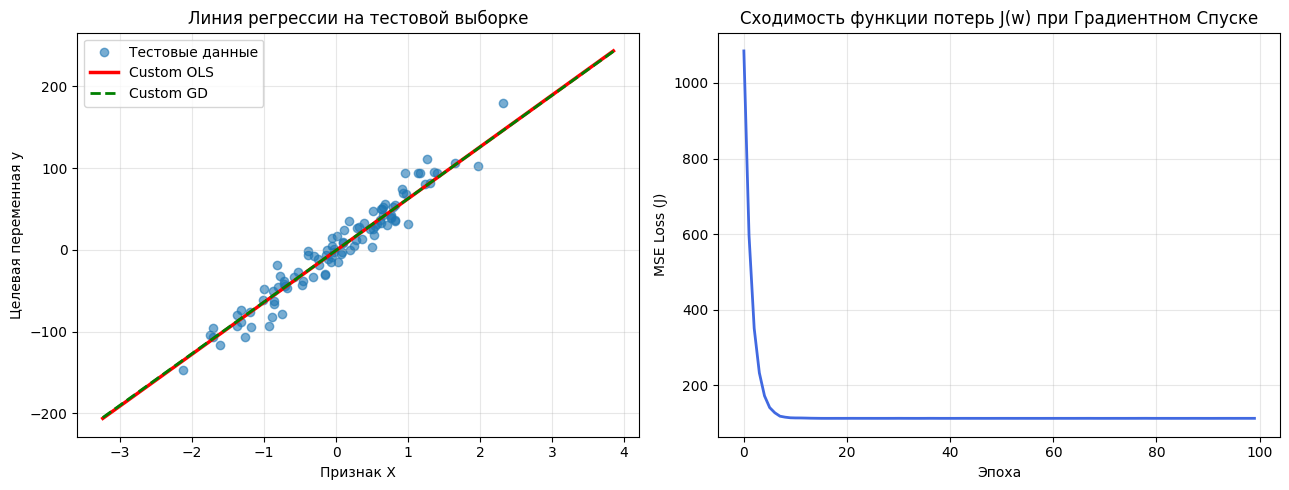

In [3]:
# Генерируем синтетический датасет
X, y = make_regression(n_samples=500, n_features=1, noise=15.0, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 1. Обучаем аналитическую версию (OLS)
model_ols = CustomLinearRegression(method='ols').fit(X_train, y_train)

# 2. Обучаем градиентную версию (Mini-Batch GD)
model_gd = CustomLinearRegression(method='gd', lr=0.05, epochs=100, batch_size=64).fit(X_train, y_train)

# 3. Эталон из scikit-learn
sk_lin = LinearRegression().fit(X_train, y_train)

print(f"[Custom OLS]  w0 = {model_ols.intercept_:.4f}, w1 = {model_ols.weights_[0]:.4f} | Test R2 = {model_ols.score(X_test, y_test):.4f}")
print(f"[Custom GD]   w0 = {model_gd.intercept_:.4f}, w1 = {model_gd.weights_[0]:.4f} | Test R2 = {model_gd.score(X_test, y_test):.4f}")
print(f"[Sklearn OLS] w0 = {sk_lin.intercept_:.4f}, w1 = {sk_lin.coef_[0]:.4f} | Test R2 = {sk_lin.score(X_test, y_test):.4f}")

# Визуализация линии регрессии и сходимости градиентного спуска
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(X_test, y_test, alpha=0.6, label="Тестовые данные")
x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
axes[0].plot(x_line, model_ols.predict(x_line), color="red", linewidth=2.5, label="Custom OLS")
axes[0].plot(x_line, model_gd.predict(x_line), color="green", linestyle="--", linewidth=2, label="Custom GD")
axes[0].set_title("Линия регрессии на тестовой выборке")
axes[0].set_xlabel("Признак X")
axes[0].set_ylabel("Целевая переменная y")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(model_gd.loss_history_, color="royalblue", linewidth=2)
axes[1].set_title("Сходимость функции потерь J(w) при Градиентном Спуске")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("MSE Loss (J)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()